### **Statistical Inference LAB**
#### **STATISTICAL ANALYSIS AND PREDICTION OF BANK CUSTOMER TERM DEPOSIT SUBSCRIPTION**

#### Name: Bhomick Debiya
#### Roll No: 32
#### Batch: B1-B2
#### Branch: CSE(AIDS)

#### **STATISTICAL ANALYSIS AND PREDICTION OF BANK CUSTOMER TERM DEPOSIT SUBSCRIPTION**

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import urllib.request
import os

#### Practical-1 Web Scraping

In [2]:
url = "https://archive.ics.uci.edu/static/publ/222/bank+marketing.zip"

urllib.request.urlretrieve(url, "bank_marketing.zip")

with zipfile.ZipFile("bank_marketing.zip", "r") as zip_ref:
    zip_ref.extractall("bank_data")

os.listdir("bank_data")

['bank-additional.zip', 'bank.zip']

In [3]:
# Load Dataset
with zipfile.ZipFile("bank_data/bank.zip", "r") as zip_ref:
    zip_ref.extract("bank-full.csv", "bank_data")

df = pd.read_csv("bank_data/bank-full.csv", sep=";")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (45211, 17)


In [5]:
# Dataset Information
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (45211, 17)

Columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data Types:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [52]:
# Basic Statistical Information
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [7]:
# Target variable y - whether the customer subscribed to a term deposit
print(df["y"].value_counts())

print("\nPercentage:")
print(df["y"].value_counts(normalize=True) * 100)

y
no     39922
yes     5289
Name: count, dtype: int64

Percentage:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


#### Practical 02 Data Cleaning, Descriptive Statistics & Visualization

In [8]:
# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [9]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (45211, 17)


In [10]:
# Descriptive Statistics
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    print("\n", column)
    print("Mean:", df[column].mean())
    print("Median:", df[column].median())
    print("Mode:", df[column].mode()[0])
    print("Variance:", df[column].var())
    print("Standard Deviation:", df[column].std())
    print("Q1:", df[column].quantile(0.25))
    print("Q2:", df[column].quantile(0.50))
    print("Q3:", df[column].quantile(0.75))


 age
Mean: 40.93621021432837
Median: 39.0
Mode: 32
Variance: 112.75810728286069
Standard Deviation: 10.618762040975431
Q1: 33.0
Q2: 39.0
Q3: 48.0

 balance
Mean: 1362.2720576850766
Median: 448.0
Mode: 0
Variance: 9270598.954472754
Standard Deviation: 3044.7658291686002
Q1: 72.0
Q2: 448.0
Q3: 1428.0

 day
Mean: 15.80641879188693
Median: 16.0
Mode: 20
Variance: 69.26360931798914
Standard Deviation: 8.322476153044185
Q1: 8.0
Q2: 16.0
Q3: 21.0

 duration
Mean: 258.1630797814691
Median: 180.0
Mode: 124
Variance: 66320.57409008514
Standard Deviation: 257.52781226517095
Q1: 103.0
Q2: 180.0
Q3: 319.0

 campaign
Mean: 2.763840658246887
Median: 2.0
Mode: 1
Variance: 9.597733393240357
Standard Deviation: 3.0980208832802205
Q1: 1.0
Q2: 2.0
Q3: 3.0

 pdays
Mean: 40.19782796222158
Median: -1.0
Mode: -1
Variance: 10025.765773651037
Standard Deviation: 100.1287459906047
Q1: -1.0
Q2: -1.0
Q3: -1.0

 previous
Mean: 0.5803233726305546
Median: 0.0
Mode: 0
Variance: 5.305840647474768
Standard Deviation: 2

In [11]:
# Summary Statistics table
stats = df[numeric_columns].describe().T

stats["variance"] = df[numeric_columns].var()
stats["mode"] = df[numeric_columns].mode().iloc[0]

stats

,count,mean,std,min,25%,50%,75%,max,variance,mode
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0,1.127581e+02,32
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0,9.270599e+06,0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0,6.926361e+01,20
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0,6.632057e+04,124
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0,9.597733e+00,1
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0,1.002577e+04,-1
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0,5.305841e+00,0


Visualization

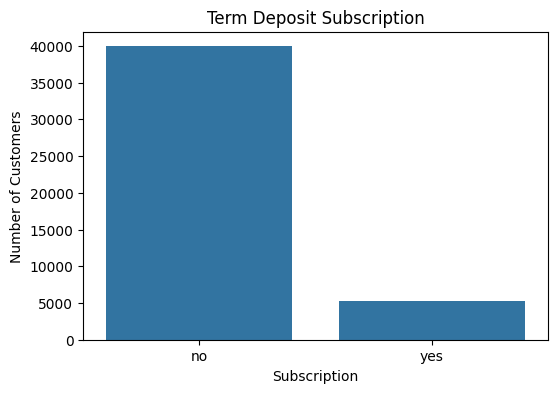

In [12]:
# Subscription Distribution
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="y")
plt.title("Term Deposit Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.show()

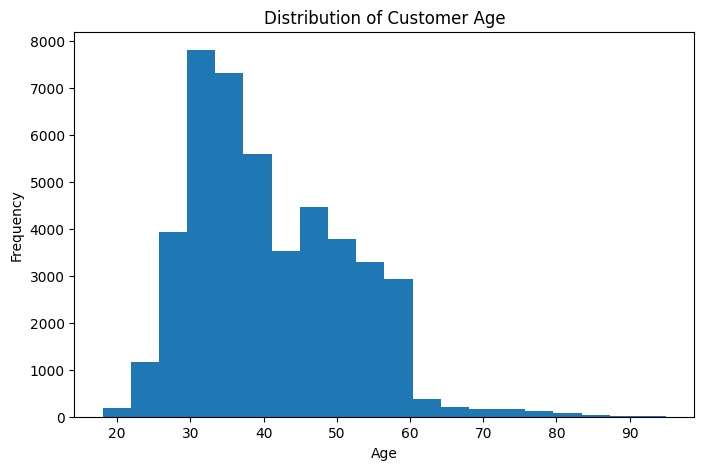

In [13]:
# Age Distribution
plt.figure(figsize=(8,5))
plt.hist(df["age"], bins=20)
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

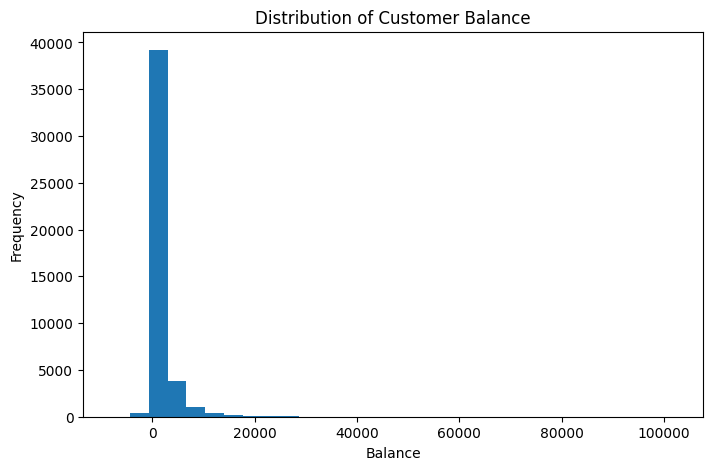

In [14]:
# Balance Distribution
plt.figure(figsize=(8,5))
plt.hist(df["balance"], bins=30)
plt.title("Distribution of Customer Balance")
plt.xlabel("Balance")
plt.ylabel("Frequency")
plt.show()

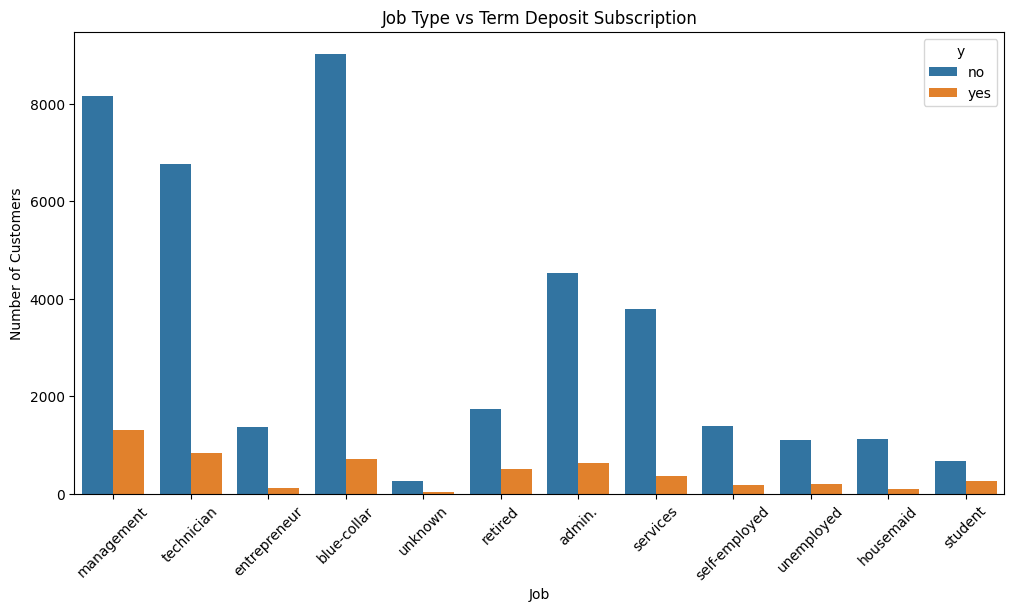

In [15]:
# Job vs Subscription
plt.figure(figsize=(12,6))
sns.countplot(data=df, x="job", hue="y")
plt.xticks(rotation=45)
plt.title("Job Type vs Term Deposit Subscription")
plt.xlabel("Job")
plt.ylabel("Number of Customers")
plt.show()

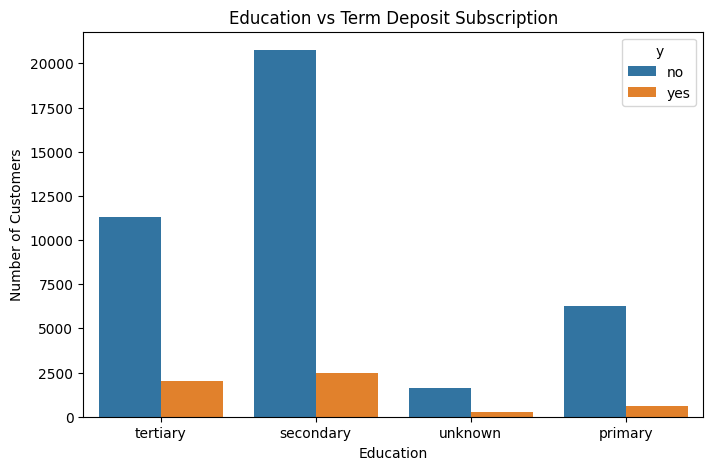

In [16]:
# Education vs subscription
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="education", hue="y")
plt.title("Education vs Term Deposit Subscription")
plt.xlabel("Education")
plt.ylabel("Number of Customers")
plt.show()

In [17]:
# Subscription rate by job
subscription_rate = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

subscription_rate

y,no,yes
job,,
admin.,87.797331,12.202669
blue-collar,92.725031,7.274969
entrepreneur,91.728312,8.271688
housemaid,91.209677,8.790323
management,86.244449,13.755551
retired,77.208481,22.791519
self-employed,88.157061,11.842939
services,91.116996,8.883004
student,71.321962,28.678038


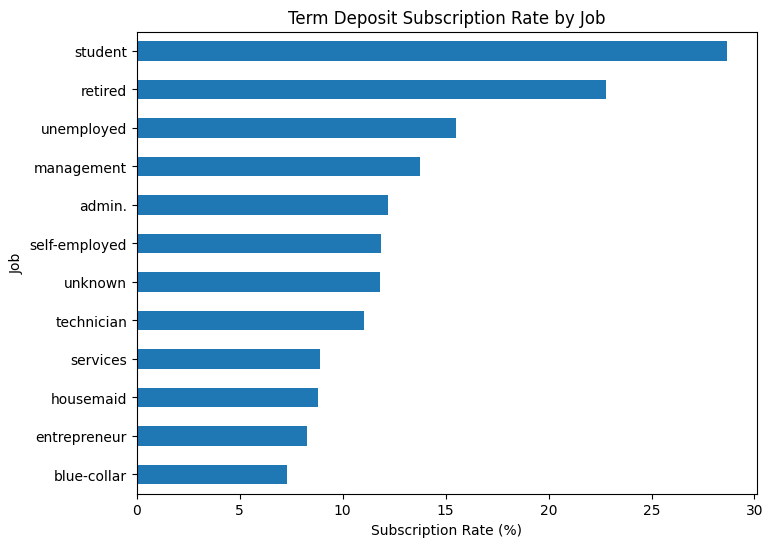

In [18]:
# Plot subscription rate
subscription_rate["yes"].sort_values().plot(
    kind="barh",
    figsize=(8,6)
)

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")
plt.show()

#### Practical 03 Probability Distribution & Random Sampling

In [19]:
# Random Sample
sample = df.sample(n=100, random_state=42)

sample.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
3776,40,blue-collar,married,secondary,no,580,yes,no,unknown,16,may,192,1,-1,0,unknown,no
9928,47,services,single,secondary,no,3644,no,no,unknown,9,jun,83,2,-1,0,unknown,no
33409,25,student,single,tertiary,no,538,yes,no,cellular,20,apr,226,1,-1,0,unknown,no
31885,42,management,married,tertiary,no,1773,no,no,cellular,9,apr,311,1,336,1,failure,no
15738,56,management,married,tertiary,no,217,no,yes,cellular,21,jul,121,2,-1,0,unknown,no


In [20]:
# Compare sample and population mean
print("Population Mean Age:", df["age"].mean())
print("Sample Mean Age:", sample["age"].mean())

print("\nPopulation Mean Balance:", df["balance"].mean())
print("Sample Mean Balance:", sample["balance"].mean())

Population Mean Age: 40.93621021432837
Sample Mean Age: 40.4

Population Mean Balance: 1362.2720576850766
Sample Mean Balance: 1182.7


In [21]:
# Binomial Distribution
p = (df["y"] == "yes").mean()

print("Probability of Subscription:", p)
print("Probability of No Subscription:", 1 - p)

Probability of Subscription: 0.11698480458295547
Probability of No Subscription: 0.8830151954170445


In [22]:
#Binomial probability
from scipy.stats import binom

n = 10
k = 2

probability = binom.pmf(k, n, p)

print("Probability of exactly 2 subscriptions among 10 customers:", probability)

Probability of exactly 2 subscriptions among 10 customers: 0.22762336505761527


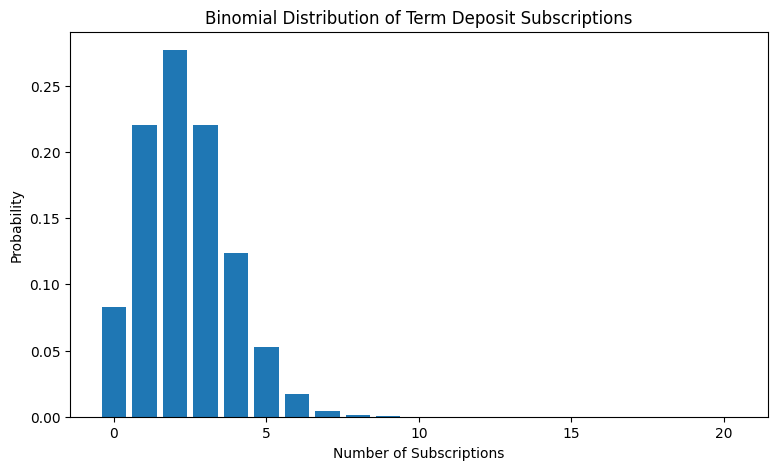

In [23]:
# Binomial Distribution Visualization
n = 20

x = np.arange(0, n + 1)
probabilities = binom.pmf(x, n, p)

plt.figure(figsize=(9,5))
plt.bar(x, probabilities)
plt.title("Binomial Distribution of Term Deposit Subscriptions")
plt.xlabel("Number of Subscriptions")
plt.ylabel("Probability")
plt.show()

Random Sampling Techniques

In [24]:
# Simple Random Sampling
simple_random_sample = df.sample(n=100, random_state=42)

print(simple_random_sample.shape)
simple_random_sample.head()

(100, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
3776,40,blue-collar,married,secondary,no,580,yes,no,unknown,16,may,192,1,-1,0,unknown,no
9928,47,services,single,secondary,no,3644,no,no,unknown,9,jun,83,2,-1,0,unknown,no
33409,25,student,single,tertiary,no,538,yes,no,cellular,20,apr,226,1,-1,0,unknown,no
31885,42,management,married,tertiary,no,1773,no,no,cellular,9,apr,311,1,336,1,failure,no
15738,56,management,married,tertiary,no,217,no,yes,cellular,21,jul,121,2,-1,0,unknown,no


In [25]:
# Systematic Sampling
step = len(df) // 100

systematic_sample = df.iloc[::step].head(100)

print(systematic_sample.shape)
systematic_sample.head()

(100, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
452,46,management,divorced,unknown,no,2,yes,no,unknown,6,may,187,1,-1,0,unknown,no
904,33,management,married,tertiary,no,442,yes,no,unknown,7,may,463,1,-1,0,unknown,no
1356,27,services,married,primary,no,91,yes,no,unknown,8,may,168,2,-1,0,unknown,no
1808,26,management,single,tertiary,no,1326,yes,no,unknown,9,may,70,1,-1,0,unknown,no


In [26]:
# Stratified Sampling
from sklearn.model_selection import train_test_split

stratified_sample, _ = train_test_split(
    df,
    train_size=100,
    stratify=df["y"],
    random_state=42
)

print(stratified_sample["y"].value_counts())

y
no     88
yes    12
Name: count, dtype: int64


#### Practical 04 Central Limit Theorem

In [27]:
# Generating sample means
sample_means = []

for i in range(1000):
    sample = df["age"].sample(n=50, random_state=i)
    sample_means.append(sample.mean())

sample_means = np.array(sample_means)

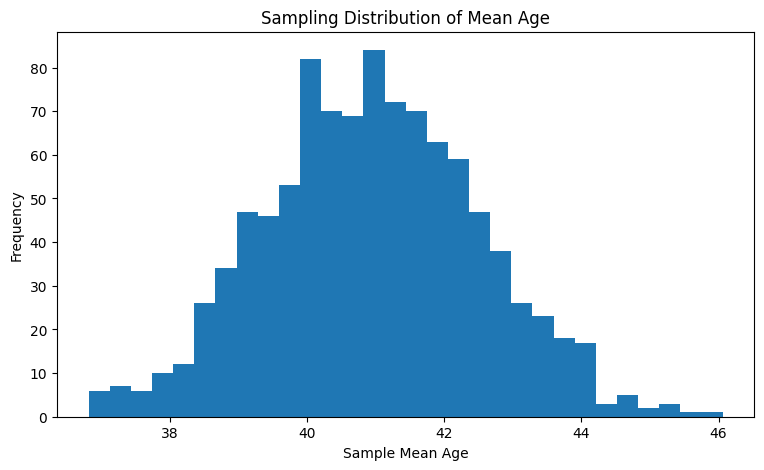

In [28]:
# Plot sampling distribution
plt.figure(figsize=(9,5))
plt.hist(sample_means, bins=30)
plt.title("Sampling Distribution of Mean Age")
plt.xlabel("Sample Mean Age")
plt.ylabel("Frequency")
plt.show()

In [29]:
# Compare population and sample means
print("Population Mean:", df["age"].mean())
print("Mean of Sample Means:", sample_means.mean())
print("Standard Deviation of Sample Means:", sample_means.std())

Population Mean: 40.93621021432837
Mean of Sample Means: 40.95296
Standard Deviation of Sample Means: 1.5577062747514372


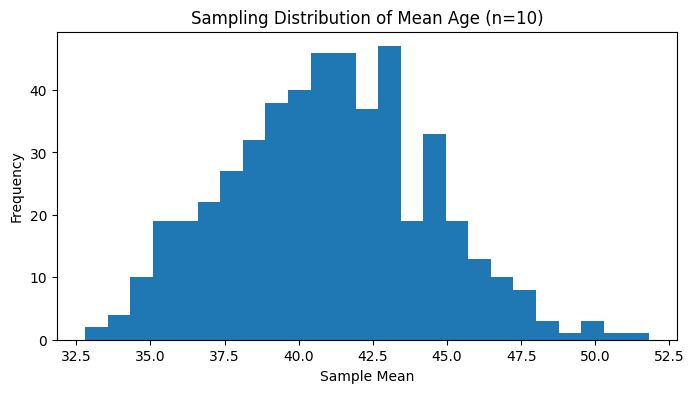

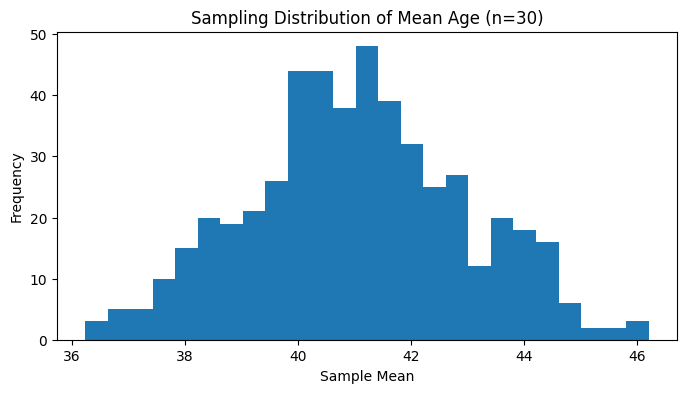

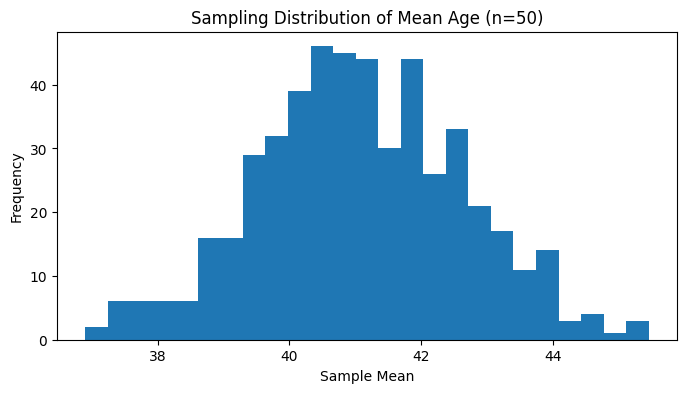

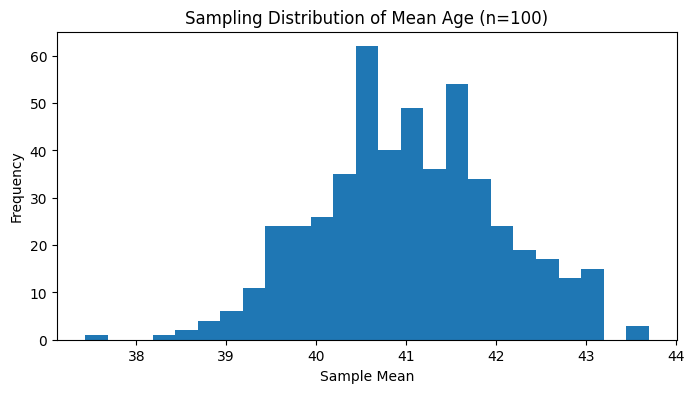

In [30]:
# CLT with Different Sample Sizes
sample_sizes = [10, 30, 50, 100]

for size in sample_sizes:
    means = []

    for i in range(500):
        sample = df["age"].sample(n=size, random_state=i)
        means.append(sample.mean())

    plt.figure(figsize=(8,4))
    plt.hist(means, bins=25)
    plt.title(f"Sampling Distribution of Mean Age (n={size})")
    plt.xlabel("Sample Mean")
    plt.ylabel("Frequency")
    plt.show()

### **Practical 05: Confidence Intervals and Hypothesis Testing**

#### **1. Aim**
To estimate population parameters using confidence intervals and to perform hypothesis testing (One-Sample Z-test and One-Sample t-test) to analyze bank customer characteristics and their subscription behavior.

---

#### **2. Confidence Intervals (CI)**


#### **3. One-Sample Z-test vs. One-Sample t-test**



#### **4. Hypothesis Testing Framework**


#### **5. Decision-Making Metrics**
* **p-value:** The probability of obtaining a test statistic at least as extreme as the one observed, assuming $H_0$ is true. If $\text{p-value} \le \alpha$, we reject $H_0$.
* **Significance Level ($\alpha$):** The probability of committing a Type I error (rejecting a true $H_0$). Typically set to $0.05$.

---

#### **6. Key Formulas**

* **Z-statistic Formula:**
  $$Z = \frac{\bar{x} - \mu_0}{\frac{\sigma}{\sqrt{n}}}$$

* **t-statistic Formula:**
  $$t = \frac{\bar{x} - \mu_0}{\frac{s}{\sqrt{n}}}$$

## Task 1: Select Variable and Sample




In [31]:
# Step 1: Extract a random sample of size n=50 from 'age' column
age_sample = df['age'].sample(n=50, random_state=42)

# Step 2: Calculate basic sample statistics
sample_mean = age_sample.mean()
sample_std = age_sample.std()
sample_size = len(age_sample)

# Step 3: Print sample statistics
print("--- Sample Statistics (n=50) ---")
print(f"Sample Size (n): {sample_size}")
print(f"Sample Mean: {sample_mean:.4f}")
print(f"Sample Standard Deviation: {sample_std:.4f}")


--- Sample Statistics (n=50) ---
Sample Size (n): 50
Sample Mean: 40.5200
Sample Standard Deviation: 10.5293


## Task 2: Calculate Confidence Interval




**Reasoning**:
Compute the 95% Confidence Interval for the population mean age of bank customers using a t-critical value from the scipy.stats library.



**Reasoning**:
Perform a One-Sample t-test on the sample of customer ages using a hypothesized population mean of 40 and a significance level of 0.05.



In [32]:
from scipy.stats import ttest_1samp

# 1. Define the hypothesized population mean
null_mean = 40.0
alpha = 0.05

# 2. Perform the one-sample t-test
t_stat, p_val = ttest_1samp(age_sample, popmean=null_mean)

# 3. Print the results clearly
print("--- One-Sample t-test Results ---")
print(f"Hypothesized Mean (H0): {null_mean}")
print(f"Calculated t-statistic: {t_stat:.4f}")
print(f"Two-tailed p-value: {p_val:.4f}")

# 4. Conditional check to reject or fail to reject the null hypothesis
if p_val < alpha:
    print(f"Conclusion: Since the p-value ({p_val:.4f}) is less than the significance level alpha ({alpha}), we REJECT the null hypothesis.")
    print("There is a statistically significant difference between the sample mean age and the hypothesized mean of 40 years.")
else:
    print(f"Conclusion: Since the p-value ({p_val:.4f}) is greater than or equal to the significance level alpha ({alpha}), we FAIL TO REJECT the null hypothesis.")
    print("There is no statistically significant difference between the sample mean age and the hypothesized mean of 40 years.")

--- One-Sample t-test Results ---
Hypothesized Mean (H0): 40.0
Calculated t-statistic: 0.3492
Two-tailed p-value: 0.7284
Conclusion: Since the p-value (0.7284) is greater than or equal to the significance level alpha (0.05), we FAIL TO REJECT the null hypothesis.
There is no statistically significant difference between the sample mean age and the hypothesized mean of 40 years.


In [33]:
from scipy.stats import t

# Degrees of freedom
df_val = sample_size - 1

# t-critical value for 95% confidence level (two-tailed)
t_critical = t.ppf(0.975, df=df_val)

# Standard Error of the Mean (SEM)
sem = sample_std / np.sqrt(sample_size)

# Margin of Error (ME)
margin_of_error = t_critical * sem

# Confidence Interval
confidence_interval = (sample_mean - margin_of_error, sample_mean + margin_of_error)

print("--- 95% Confidence Interval Calculation ---")
print(f"Degrees of Freedom: {df_val}")
print(f"t-critical value: {t_critical:.4f}")
print(f"Standard Error (SEM): {sem:.4f}")
print(f"Margin of Error (ME): {margin_of_error:.4f}")
print(f"95% Confidence Interval for Population Mean: ({confidence_interval[0]:.4f}, {confidence_interval[1]:.4f})")

--- 95% Confidence Interval Calculation ---
Degrees of Freedom: 49
t-critical value: 2.0096
Standard Error (SEM): 1.4891
Margin of Error (ME): 2.9924
95% Confidence Interval for Population Mean: (37.5276, 43.5124)


## Task 4: One-Sample Z-test Approximation




In [34]:
from scipy.stats import norm
import numpy as np

# 1. Define hypothesized population mean and sample parameters
null_mean = 40.0
alpha = 0.05

# 2. Compute Z-statistic manually using sample standard deviation as a proxy for population standard deviation
sem_approx = sample_std / np.sqrt(sample_size)
z_stat = (sample_mean - null_mean) / sem_approx

# 3. Calculate the two-tailed p-value
p_val_z = 2 * (1 - norm.cdf(abs(z_stat)))

# 4. Print results
print("--- One-Sample Z-test Approximation Results ---")
print(f"Hypothesized Mean (H0): {null_mean}")
print(f"Calculated Z-statistic: {z_stat:.4f}")
print(f"Two-tailed p-value: {p_val_z:.4f}")

# 5. Make statistical decision
if p_val_z < alpha:
    print(f"Decision: Reject H0 at alpha = {alpha}.")
else:
    print(f"Decision: Fail to reject H0 at alpha = {alpha}.")

# 6. Explanation of assumptions and limitations
print("\n--- Statistical Discussion ---")
print("Assumptions:")
print("- Central Limit Theorem (CLT): Since our sample size (n=50) is greater than 30, the sampling distribution of the mean is approximately normal.")
print("- Standard Deviation Proxy: We assume the sample standard deviation (s) is a reasonable proxy for the unknown population standard deviation (sigma).")
print("\nLimitations:")
print("- Using the sample standard deviation (s) introduces extra variability, meaning the t-distribution is theoretically more appropriate for n=50.")
print("- Z-test approximations tend to underestimate the tails (leading to slightly smaller p-values than t-tests), though at n=50 the difference is minimal.")

--- One-Sample Z-test Approximation Results ---
Hypothesized Mean (H0): 40.0
Calculated Z-statistic: 0.3492
Two-tailed p-value: 0.7269
Decision: Fail to reject H0 at alpha = 0.05.

--- Statistical Discussion ---
Assumptions:
- Central Limit Theorem (CLT): Since our sample size (n=50) is greater than 30, the sampling distribution of the mean is approximately normal.
- Standard Deviation Proxy: We assume the sample standard deviation (s) is a reasonable proxy for the unknown population standard deviation (sigma).

Limitations:
- Using the sample standard deviation (s) introduces extra variability, meaning the t-distribution is theoretically more appropriate for n=50.
- Z-test approximations tend to underestimate the tails (leading to slightly smaller p-values than t-tests), though at n=50 the difference is minimal.


## Two-Sample Independent t-test

### Subtask:
Perform a two-sample independent t-test to compare customer balance between subscribers and non-subscribers.


In [35]:
from scipy.stats import ttest_ind

# 1. Separate the customer 'balance' into two groups
balance_yes = df[df['y'] == 'yes']['balance']
balance_no = df[df['y'] == 'no']['balance']

# 2. Perform Welch's t-test (equal_var=False)
t_stat_ind, p_val_ind = ttest_ind(balance_yes, balance_no, equal_var=False)

# 3. Print the results
print("--- Two-Sample Independent t-test (Welch's t-test) ---")
print(f"Subscribers mean balance: {balance_yes.mean():.4f} (n={len(balance_yes)})")
print(f"Non-subscribers mean balance: {balance_no.mean():.4f} (n={len(balance_no)})")
print(f"Calculated t-statistic: {t_stat_ind:.4f}")
print(f"Two-tailed p-value: {p_val_ind:.4e}")

# 4. Decision making
alpha = 0.05
if p_val_ind < alpha:
    print(f"\nConclusion: Since the p-value is less than the significance level alpha ({alpha}), we REJECT the null hypothesis.")
    print("There is a statistically significant difference in customer balance between subscribers and non-subscribers.")
else:
    print(f"\nConclusion: Since the p-value is greater than or equal to the significance level alpha ({alpha}), we FAIL TO REJECT the null hypothesis.")
    print("There is no statistically significant difference in customer balance between subscribers and non-subscribers.")

--- Two-Sample Independent t-test (Welch's t-test) ---
Subscribers mean balance: 1804.2679 (n=5289)
Non-subscribers mean balance: 1303.7150 (n=39922)
Calculated t-statistic: 9.9335
Two-tailed p-value: 4.3837e-23

Conclusion: Since the p-value is less than the significance level alpha (0.05), we REJECT the null hypothesis.
There is a statistically significant difference in customer balance between subscribers and non-subscribers.


Education levels: ['tertiary' 'secondary' 'unknown' 'primary']

--- One-Way ANOVA Results ---
Calculated F-statistic: 116.6821
p-value: 2.8495e-75
Conclusion: Since the p-value is less than 0.05, we REJECT the null hypothesis.
There is a statistically significant difference in customer balance across different education levels.


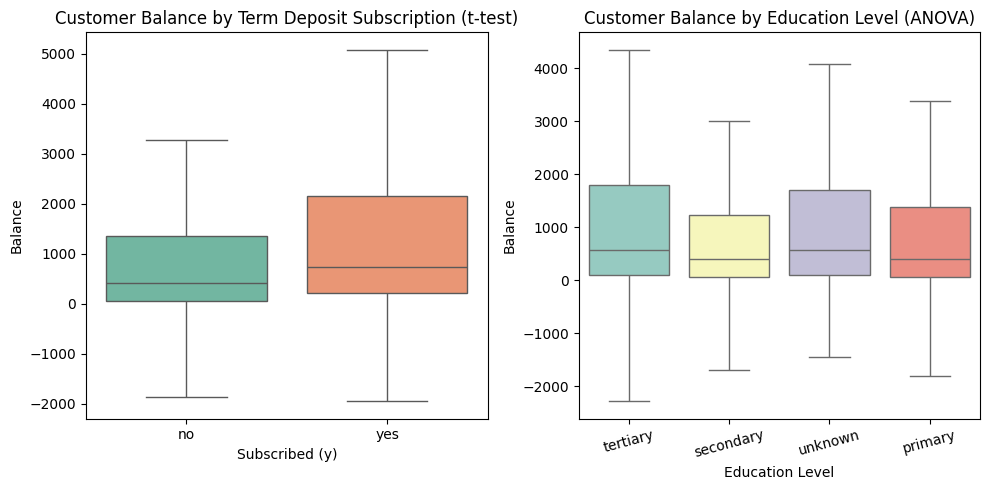

In [53]:
from scipy.stats import f_oneway
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. ANOVA Test: Balance across different Education levels ---
# Get unique education levels
education_levels = df['education'].unique()
print("Education levels:", education_levels)

# Group balances by education level
education_groups = [df[df['education'] == edu]['balance'] for edu in education_levels]

# Perform ANOVA
f_stat, p_val_anova = f_oneway(*education_groups)

print("\n--- One-Way ANOVA Results ---")
print(f"Calculated F-statistic: {f_stat:.4f}")
print(f"p-value: {p_val_anova:.4e}")

alpha = 0.05
if p_val_anova < alpha:
    print(f"Conclusion: Since the p-value is less than {alpha}, we REJECT the null hypothesis.")
    print("There is a statistically significant difference in customer balance across different education levels.")
else:
    print(f"Conclusion: Since the p-value is greater than or equal to {alpha}, we FAIL TO REJECT the null hypothesis.")
    print("There is no statistically significant difference in customer balance across different education levels.")

# --- 2. Visualizations ---
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Box plot for t-test: Balance vs Term Deposit Subscription
sns.boxplot(ax=axes[0], data=df, x='y', y='balance', hue='y', palette='Set2', legend=False, showfliers=False)
axes[0].set_title("Customer Balance by Term Deposit Subscription (t-test)")
axes[0].set_xlabel("Subscribed (y)")
axes[0].set_ylabel("Balance")

# Box plot for ANOVA: Balance vs Education level
sns.boxplot(ax=axes[1], data=df, x='education', y='balance', hue='education', palette='Set3', legend=False, showfliers=False)
axes[1].set_title("Customer Balance by Education Level (ANOVA)")
axes[1].set_xlabel("Education Level")
axes[1].set_ylabel("Balance")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

# Task


## Chi-Square Test of Independence

### Subtask:
Analyze the statistical relationship between the categorical variables 'job' and 'y' using a Chi-Square Test of Independence.


In [37]:
from scipy.stats import chi2_contingency

# 1. Create a contingency table between 'job' and 'y'
contingency_table = pd.crosstab(df['job'], df['y'])
print("--- Contingency Table (job vs y) ---")
print(contingency_table)

# 2. Perform the Chi-Square Test of Independence
chi2_stat, p_val_chi2, dof, expected = chi2_contingency(contingency_table)

# 3. Print results
print("\n--- Chi-Square Test Results ---")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"p-value: {p_val_chi2:.4e}")
print(f"Degrees of Freedom: {dof}")
print("\nExpected Frequencies Matrix:")
print(pd.DataFrame(expected, index=contingency_table.index, columns=contingency_table.columns))

# 4. Statistical Decision
alpha = 0.05
if p_val_chi2 < alpha:
    print(f"\nConclusion: Since the p-value is less than the significance level alpha ({alpha}), we REJECT the null hypothesis.")
    print("There is a statistically significant association between a customer's job and their term deposit subscription behavior.")
else:
    print(f"\nConclusion: Since the p-value is greater than or equal to the significance level alpha ({alpha}), we FAIL TO REJECT the null hypothesis.")
    print("There is no statistically significant association between a customer's job and their term deposit subscription behavior.")

--- Contingency Table (job vs y) ---
y                no   yes
job                      
admin.         4540   631
blue-collar    9024   708
entrepreneur   1364   123
housemaid      1131   109
management     8157  1301
retired        1748   516
self-employed  1392   187
services       3785   369
student         669   269
technician     6757   840
unemployed     1101   202
unknown         254    34

--- Chi-Square Test Results ---
Chi-Square Statistic: 836.1055
p-value: 3.3371e-172
Degrees of Freedom: 11

Expected Frequencies Matrix:
y                       no          yes
job                                    
admin.         4566.071576   604.928424
blue-collar    8593.503882  1138.496118
entrepreneur   1313.043596   173.956404
housemaid      1094.938842   145.061158
management     8351.557718  1106.442282
retired        1999.146402   264.853598
self-employed  1394.280994   184.719006
services       3668.045122   485.954878
student         828.268253   109.731747
technician     6708.2

--- Covariance Matrix ---
                  age       balance         day      duration    campaign  \
age        112.758107  3.161477e+03   -0.805979    -12.711716    0.156601   
balance   3161.476700  9.270599e+06  114.095467  16905.750545 -137.513232   
day         -0.805979  1.140955e+02   69.263609    -64.740317    4.189519   
duration   -12.711716  1.690575e+04  -64.740317  66320.574090  -67.471794   
campaign     0.156601 -1.375132e+02    4.189519    -67.471794    9.597733   
pdays      -25.260550  1.047322e+03  -77.535404    -40.349073  -27.492386   
previous     0.031512  1.169395e+02   -0.991307      0.713654   -0.234459   

                 pdays    previous  
age         -25.260550    0.031512  
balance    1047.321715  116.939527  
day         -77.535404   -0.991307  
duration    -40.349073    0.713654  
campaign    -27.492386   -0.234459  
pdays     10025.765774  104.899902  
previous    104.899902    5.305841  

--- Correlation Matrix ---
               age   balance     

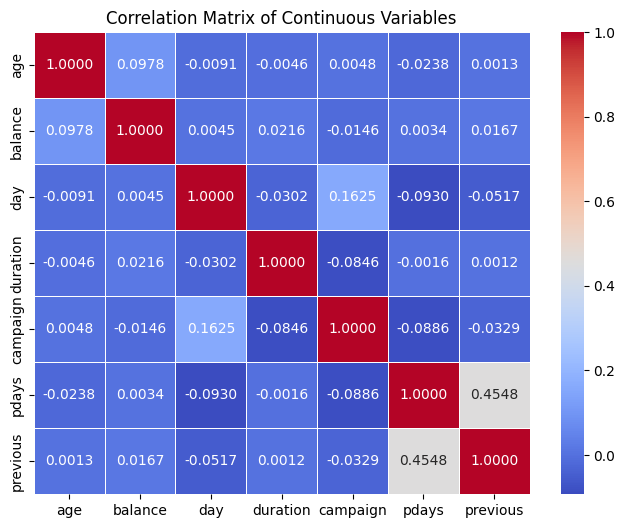

In [38]:
# Select continuous variables
continuous_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

# Compute Covariance Matrix
covariance_matrix = df[continuous_cols].cov()
print("--- Covariance Matrix ---")
print(covariance_matrix)

# Compute Correlation Matrix
correlation_matrix = df[continuous_cols].corr()
print("\n--- Correlation Matrix ---")
print(correlation_matrix)

# Plot Heatmap of Correlation Matrix
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.4f', linewidths=0.5)
plt.title("Correlation Matrix of Continuous Variables")
plt.show()

### **Practical 6, Part C: Hypothesis Testing for Correlation**

In [39]:
from scipy.stats import pearsonr
import pandas as pd
import os

# Safely load df if missing from runtime state
if 'df' not in globals():
    if os.path.exists('bank_data/bank-full.csv'):
        df = pd.read_csv('bank_data/bank-full.csv', sep=';')
    else:
        raise FileNotFoundError('Please run Practical 1 first to download the CSV.')

# Select variables
x_var = df['age']
y_var = df['balance']

# 1. Pearson Correlation Test
pearson_corr, pearson_p_val = pearsonr(x_var, y_var)
print('--- Pearson Correlation Test ---')
print(f'Pearson correlation coefficient (r): {pearson_corr:.4f}')
print(f'p-value: {pearson_p_val:.4e}')

# Decision
alpha = 0.05
if pearson_p_val < alpha:
    print(f'Decision: Reject H0 at alpha = {alpha}. The linear correlation is statistically significant.')
else:
    print(f'Decision: Fail to reject H0 at alpha = {alpha}. The linear correlation is not statistically significant.')

--- Pearson Correlation Test ---
Pearson correlation coefficient (r): 0.0978
p-value: 1.8470e-96
Decision: Reject H0 at alpha = 0.05. The linear correlation is statistically significant.


In [40]:
from scipy.stats import spearmanr
import pandas as pd
import os

# Safely load df if missing from runtime state
if 'df' not in globals():
    if os.path.exists('bank_data/bank-full.csv'):
        df = pd.read_csv('bank_data/bank-full.csv', sep=';')
    else:
        raise FileNotFoundError('Please run Practical 1 first to download the CSV.')

# Select variables
x_var = df['age']
y_var = df['balance']

# 2. Spearman Rank Correlation Test
spearman_corr, spearman_p_val = spearmanr(x_var, y_var)
print('--- Spearman Rank Correlation Test ---')
print(f'Spearman rank correlation coefficient (rho): {spearman_corr:.4f}')
print(f'p-value: {spearman_p_val:.4e}')

# Decision
alpha = 0.05
if spearman_p_val < alpha:
    print(f'Decision: Reject H0 at alpha = {alpha}. The monotonic relationship is statistically significant.')
else:
    print(f'Decision: Fail to reject H0 at alpha = {alpha}. The monotonic relationship is not statistically significant.')

--- Spearman Rank Correlation Test ---
Spearman rank correlation coefficient (rho): 0.0964
p-value: 9.3611e-94
Decision: Reject H0 at alpha = 0.05. The monotonic relationship is statistically significant.


### **Practical 6, Part D: Two-Way ANOVA (Analysis of Variance)**

**Aim:** To study the effects of two categorical independent variables (`marital` status and `education` level) on a continuous dependent variable (`age`) using a Two-Way ANOVA model.

In [41]:
# Consolidated Two-Way ANOVA Implementation
import statsmodels.api as sm
from statsmodels.formula.api import ols
import pandas as pd
import os

# Safely load df if missing from runtime state
if 'df' not in globals():
    if os.path.exists('bank_data/bank-full.csv'):
        df = pd.read_csv('bank_data/bank-full.csv', sep=';')
    else:
        raise FileNotFoundError('Please run Practical 1 first to download the CSV.')

# Fit the Two-Way ANOVA model
# Dependent variable: age
# Categorical independent variables: marital status, education level
formula = 'age ~ C(marital) * C(education)'
model = ols(formula, data=df).fit()

# Display the ANOVA table
anova_table = sm.stats.anova_lm(model, typ=2)
print("--- Two-Way ANOVA Table ---")
print(anova_table)

--- Two-Way ANOVA Table ---
                               sum_sq       df            F         PR(>F)
C(marital)               8.541621e+05      2.0  4833.921042   0.000000e+00
C(education)             1.325634e+05      3.0   500.140057  9.165906e-320
C(marital):C(education)  1.417517e+04      6.0    26.740295   5.464519e-32
Residual                 3.993370e+06  45199.0          NaN            NaN


### **Statistical Significance Analysis**
Below we observe the F-statistics and corresponding p-values for main effects and their interaction.

In [42]:
# Summarizing ANOVA decisions
for factor in ['C(marital)', 'C(education)', 'C(marital):C(education)']:
    p_val = anova_table.loc[factor, 'PR(>F)']
    print(f"{factor} p-value: {p_val:.4e}")
    if p_val < 0.05:
        print(f"-> Reject Null Hypothesis: {factor} has a statistically significant effect on Age.\n")
    else:
        print(f"-> Fail to Reject Null Hypothesis: {factor} does not have a significant effect on Age.\n")

C(marital) p-value: 0.0000e+00
-> Reject Null Hypothesis: C(marital) has a statistically significant effect on Age.

C(education) p-value: 9.1659e-320
-> Reject Null Hypothesis: C(education) has a statistically significant effect on Age.

C(marital):C(education) p-value: 5.4645e-32
-> Reject Null Hypothesis: C(marital):C(education) has a statistically significant effect on Age.



### **Practical 7: Preprocessing and Train-Test Split**

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
import pandas as pd
import urllib.request
import os

# Safely download and load the data if not in memory
if 'ins_df' not in globals():
    insurance_url = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'
    insurance_path = 'insurance.csv'
    if not os.path.exists(insurance_path):
        print('Downloading insurance dataset...')
        urllib.request.urlretrieve(insurance_url, insurance_path)
    ins_df = pd.read_csv(insurance_path)

# Separate features and target
X = ins_df.drop(columns=['charges'])
y = ins_df['charges']

# Define column types
num_cols = ['age', 'bmi', 'children']
cat_cols = ['sex', 'smoker', 'region']

# Set up preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ]
)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training set shape: {X_train.shape}')
print(f'Testing set shape: {X_test.shape}')

Training set shape: (1070, 6)
Testing set shape: (268, 6)


In [44]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Fit the preprocessing pipeline on training data
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# Initialize regression models
models = {
    'Multiple Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=1.0),
    'Decision Tree Regression': DecisionTreeRegressor(random_state=42, max_depth=5),
    'Random Forest Regression': RandomForestRegressor(random_state=42, n_estimators=100, max_depth=5)
}

# Train and evaluate models
results = []
for name, model in models.items():
    # Fit model
    model.fit(X_train_preprocessed, y_train)

    # Predict
    y_pred = model.predict(X_test_preprocessed)

    # Calculate metrics
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    results.append({
        'Model': name,
        'R2 Score': r2,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse
    })

# Create a comparison DataFrame
results_df = pd.DataFrame(results)

# Sort results by R2 Score in descending order
results_df = results_df.sort_values(by='R2 Score', ascending=False).reset_index(drop=True)

print("--- Model Evaluation Table ---")
print(results_df.to_string(index=False))

best_model_row = results_df.iloc[0]
print(f"\nBest Performing Model: {best_model_row['Model']} with R2 score of {best_model_row['R2 Score']:.4f}")

--- Model Evaluation Table ---
                     Model  R2 Score         MAE          MSE        RMSE
  Random Forest Regression  0.873488 2560.400554 1.964078e+07 4431.792034
  Decision Tree Regression  0.833610 2930.767571 2.583186e+07 5082.505544
Multiple Linear Regression  0.783593 4181.194474 3.359692e+07 5796.284659
          Lasso Regression  0.783536 4182.219786 3.360573e+07 5797.044759
          Ridge Regression  0.783281 4193.195353 3.364539e+07 5800.464938

Best Performing Model: Random Forest Regression with R2 score of 0.8735


In [45]:
import joblib
from sklearn.pipeline import Pipeline

# 1. Re-bundle the preprocessor and the best estimator into a unified inference pipeline
best_estimator = RandomForestRegressor(random_state=42, n_estimators=100, max_depth=5)

production_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', best_estimator)
])

# 2. Fit the production pipeline on the raw training dataset (to maintain easy inference input formatting)
production_pipeline.fit(X_train, y_train)

# 3. Save the model pipeline for production deployment
model_filename = 'best_insurance_model.joblib'
joblib.dump(production_pipeline, model_filename)
print(f"Success: Best-performing pipeline saved as '{model_filename}'")

Success: Best-performing pipeline saved as 'best_insurance_model.joblib'


### **Practical 7: Regression Models and Best-Model Selection**

**Aim:** Implement and compare Multiple Linear Regression, Ridge Regression, Lasso Regression, Decision Tree Regression, and Random Forest Regression models, then select the best-performing model based on $R^2$ score.

In [46]:
import pandas as pd
import numpy as np
import urllib.request
import os

# 1. Download and load the Medical Insurance Cost Prediction dataset
insurance_url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
insurance_path = "insurance.csv"

if not os.path.exists(insurance_path):
    print("Downloading insurance dataset...")
    urllib.request.urlretrieve(insurance_url, insurance_path)

ins_df = pd.read_csv(insurance_path)
print("Insurance Dataset Shape:", ins_df.shape)
print("\nFirst 5 rows:")
print(ins_df.head())

Insurance Dataset Shape: (1338, 7)

First 5 rows:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [47]:
streamlit_app_code_complete = """
import streamlit as st
import pandas as pd
import joblib
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Set page styling
st.set_page_config(
    page_title="Bank Customer & Medical Insurance Analytics Suite",
    layout="wide"
)

# Top navigation bar
tab_profile, tab_bank, tab_model, tab_predictor = st.tabs([
    "📋 Data Profile & Overview",
    "📊 Bank Dataset Dashboard",
    "🔬 Statistics & Model Selection",
    "⚕️ Insurance Premium Predictor"
])

# Load Data Helper functions
@st.cache_data
def load_bank_data():
    bank_csv_path = 'bank_data/bank-full.csv'
    if os.path.exists(bank_csv_path):
        return pd.read_csv(bank_csv_path, sep=";")
    return None

@st.cache_data
def load_insurance_data():
    ins_csv_path = 'insurance.csv'
    if os.path.exists(ins_csv_path):
        return pd.read_csv(ins_csv_path)
    return None

df_bank = load_bank_data()
df_ins = load_insurance_data()

# =====================================================================
# TAB 1: DATA PROFILE & OVERVIEW
# =====================================================================
with tab_profile:
    st.title("📋 Datasets Profile & Overview")
    st.write("Comprehensive summary of structural, quality, and meta metrics for both underlying research datasets.")

    col1, col2 = st.columns(2)

    with col1:
        st.subheader("🏦 Dataset 1: Bank Marketing Dataset")
        if df_bank is not None:
            # Metric Row
            m1, m2, m3 = st.columns(3)
            m1.metric("Row Count", f"{df_bank.shape[0]:,}")
            m2.metric("Column Count", f"{df_bank.shape[1]}")
            m3.metric("Duplicate Rows", f"{df_bank.duplicated().sum()}")

            # Null info
            st.markdown("**Missing Values per Column:**")
            nulls = df_bank.isnull().sum().to_frame(name="Null Counts")
            st.dataframe(nulls.T, use_container_width=True)

            # Data Preview
            st.markdown("**Data Head Preview:**")
            st.dataframe(df_bank.head(5), use_container_width=True)
        else:
            st.warning("Bank dataset CSV not found!")

    with col2:
        st.subheader("⚕️ Dataset 2: Medical Insurance Dataset")
        if df_ins is not None:
            # Metric Row
            m1, m2, m3 = st.columns(3)
            m1.metric("Row Count", f"{df_ins.shape[0]:,}")
            m2.metric("Column Count", f"{df_ins.shape[1]}")
            m3.metric("Duplicate Rows", f"{df_ins.duplicated().sum()}")

            # Null info
            st.markdown("**Missing Values per Column:**")
            nulls_ins = df_ins.isnull().sum().to_frame(name="Null Counts")
            st.dataframe(nulls_ins.T, use_container_width=True)

            # Data Preview
            st.markdown("**Data Head Preview:**")
            st.dataframe(df_ins.head(5), use_container_width=True)
        else:
            st.warning("Insurance dataset CSV not found!")

# =====================================================================
# TAB 2: BANK MARKETING DASHBOARD
# =====================================================================
with tab_bank:
    st.title("📊 Bank Customer Term Deposit Subscription Analysis")
    st.write("Exploratory visual representations of customer financial variables and demographics.")

    if df_bank is not None:
        col_m1, col_m2, col_m3 = st.columns(3)
        col_m1.metric("Total Customers Included", f"{len(df_bank):,}")
        sub_rate = (df_bank['y'] == 'yes').mean() * 100
        col_m2.metric("Average Term Subscription", f"{sub_rate:.2f}%")
        col_m3.metric("Avg Customer Balance", f"${df_bank['balance'].mean():,.2f}")

        col_v1, col_v2 = st.columns(2)
        with col_v1:
            st.subheader("Term Deposit Subscription Ratio")
            fig, ax = plt.subplots(figsize=(6, 3.5))
            sns.countplot(data=df_bank, x='y', palette='Set2', ax=ax)
            st.pyplot(fig)
            st.info("**Insight:** The dataset is highly imbalanced. Only ~11.7% of contacted customers chose to subscribe to a term deposit, indicating target marketing refinement is essential.")

            st.subheader("Age Distribution Profile")
            fig2, ax2 = plt.subplots(figsize=(6, 3.5))
            sns.histplot(data=df_bank, x='age', bins=20, kde=True, color='skyblue', ax=ax2)
            st.pyplot(fig2)
            st.info("**Insight:** The customer distribution peaks in the active career window between 30 and 45 years. Outreach to retired demographics is low, despite their high relative subscription rates.")

        with col_v2:
            st.subheader("Job Type Subscriptions Comparison")
            fig3, ax3 = plt.subplots(figsize=(6, 3.5))
            sns.countplot(data=df_bank, x='job', hue='y', palette='Set1', ax=ax3)
            plt.xticks(rotation=45, ha='right')
            plt.tight_layout()
            st.pyplot(fig3)
            st.info("**Insight:** Management and technician classes form the largest segment volume, but students and retired individuals exhibit higher individual conversion ratios.")

            st.subheader("Outlier-Removed Balances by Subscription")
            fig4, ax4 = plt.subplots(figsize=(6, 3.5))
            sns.boxplot(data=df_bank, x='y', y='balance', palette='pastel', ax=ax4, showfliers=False)
            st.pyplot(fig4)
            st.info("**Insight:** Subscribed customers maintain significantly higher median standing ledger balances than non-subscribers, reflecting a strong correlation between capital reserves and commitment capability.")
    else:
        st.warning("No Bank data loaded.")

# =====================================================================
# TAB 3: STATISTICS & MODEL SELECTION
# =====================================================================
with tab_model:
    st.title("🔬 Statistical Testing & Predictive Model Selection")

    st.subheader("1. Key Hypotheses & Takeaways")
    st.markdown(
        "* **One-Sample t-test on Customer Age:**\\n"
        "  * *Hypothesis:* H0: Mean Age = 40 vs H1: Mean Age != 40\\n"
        "  * *Result:* t-stat = **0.3492**, p-value = **0.7284**\\n"
        "  * *Takeaway:* **Fail to Reject H0**. The average customer age does not deviate significantly from 40.\\n\\n"
        "* **Two-Sample Independent Welch's t-test (Balances):**\\n"
        "  * *Hypothesis:* Equal means between subscribers and non-subscribers.\\n"
        "  * *Result:* t-stat = **9.9335**, p-value = **4.3837e-23**\\n"
        "  * *Takeaway:* **Reject H0**. Term deposit subscribers possess significantly higher ledger account balances.\\n\\n"
        "* **Chi-Square Test of Independence (Job vs Subscription):**\\n"
        "  * *Result:* Chi2-stat = **836.1055**, p-value = **3.3371e-172**\\n"
        "  * *Takeaway:* **Reject H0**. Job classifications are highly correlated with subscription rates.\\n\\n"
        "* **Two-Way ANOVA (Dependent: Age | Marital, Education):**\\n"
        "  * *Takeaway:* Marital status, education background, and their respective interaction coefficients all have highly significant (p < 0.05) effects on customer age."
    )

    st.markdown("---")
    st.subheader("2. Machine Learning Regression Model Performance Comparison")
    st.write("Below are the calculated validation metrics for various regression estimators trained on the Medical Insurance Dataset.")

    comparison_data = pd.DataFrame({
        'Model': [
            'Random Forest Regression',
            'Decision Tree Regression',
            'Multiple Linear Regression',
            'Lasso Regression',
            'Ridge Regression'
        ],
        'R2 Score': [0.8735, 0.8336, 0.7836, 0.7835, 0.7833],
        'MAE ($)': ['2,560.40', '2,930.77', '4,181.19', '4,182.22', '4,193.20'],
        'RMSE ($)': ['4,431.79', '5,082.51', '5,796.28', '5,797.04', '5,800.46']
    })

    col_table, col_chart = st.columns([1, 1.2])

    with col_table:
        st.markdown("**Performance Table:**")
        st.dataframe(comparison_data, use_container_width=True)
        st.success("🏆 **Best Performing Model Selected:** **Random Forest Regression** with a validation R2 score of **87.35%**.")

    with col_chart:
        st.markdown("**Model $R^2$ Comparison Chart:**")
        fig_compare, ax_compare = plt.subplots(figsize=(7, 4.3))
        chart_df = pd.DataFrame({
            'Model': ['Random Forest', 'Decision Tree', 'Linear Reg.', 'Lasso', 'Ridge'],
            'R2': [0.8735, 0.8336, 0.7836, 0.7835, 0.7833]
        })
        sns.barplot(data=chart_df, x='R2', y='Model', palette='Blues_r', ax=ax_compare)
        ax_compare.set_xlim(0, 1.0)
        ax_compare.set_xlabel("R-squared Score (Higher is Better)")
        ax_compare.set_ylabel("Algorithm")
        for i, v in enumerate(chart_df['R2']):
            ax_compare.text(v + 0.01, i, f"{v:.4f}", va='center', fontweight='bold')
        plt.tight_layout()
        st.pyplot(fig_compare)

# =====================================================================
# TAB 4: INSURANCE PREMIUM PREDICTOR
# =====================================================================
with tab_predictor:
    st.title("⚕️ Medical Insurance Premium Predictor")
    st.write("Input target customer attributes below to execute the saved production pipeline and determine estimates.")

    model_path = 'best_insurance_model.joblib'
    if os.path.exists(model_path):
        pipeline = joblib.load(model_path)
    else:
        st.error("Inference model 'best_insurance_model.joblib' missing. Execute modeling tasks first.")
        st.stop()

    with st.form("predictor_form"):
        col_f1, col_f2 = st.columns(2)
        with col_f1:
            age = st.number_input("Age", min_value=18, max_value=100, value=30, step=1)
            bmi = st.number_input("Body Mass Index (BMI)", min_value=10.0, max_value=60.0, value=25.0, step=0.1)
            children = st.number_input("Number of Dependents / Children", min_value=0, max_value=10, value=0, step=1)
        with col_f2:
            sex = st.selectbox("Biological Sex", options=["male", "female"])
            smoker = st.selectbox("Smoker Status", options=["no", "yes"])
            region = st.selectbox("US Geographic Region", options=["southwest", "southeast", "northwest", "northeast"])

        submit_button = st.form_submit_button("Predict Premium")

    if submit_button:
        input_df = pd.DataFrame([{
            'age': age,
            'sex': sex,
            'bmi': bmi,
            'children': children,
            'smoker': smoker,
            'region': region
        }])
        prediction = pipeline.predict(input_df)[0]
        st.success(f"### Estimated Annual Premium Charges: **${prediction:,.2f}**")
"""

with open('app.py', 'w') as f:
    f.write(streamlit_app_code_complete.strip())

print("Success: Recompiled 'app.py' with interactive conclusions and model comparisons!")

Success: Recompiled 'app.py' with interactive conclusions and model comparisons!


### **Restarting the Streamlit Server**
Run the cell below to terminate any active streamlit servers and restart them so that the newly added graphs and tabs are available on your URL.

In [49]:
# 1. Install Streamlit and localtunnel
!pip install -q streamlit
!npm install -q -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇
added 22 packages in 2s
⠇
⠇3 packages are looking for funding
⠇  run `npm fund` for details
⠇

In [51]:
# Restart the Streamlit background processes with the newly added pages

!pkill streamlit
!pkill lt

import subprocess
import time
import urllib.request

with open('streamlit.log', 'w') as f:
    subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.address", "127.0.0.1"], stdout=f, stderr=f)

time.sleep(5)

try:
    ip_address = urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip()
    print("=========================================================")
    print(f"YOUR TUNNEL PASSWORD (IP Address): {ip_address}")
    print("=========================================================")
except Exception as e:
    print("Could not retrieve IP address:", e)

# Let's prompt user to start localtunnel if they wish, or start it inline
print("Starting localtunnel...")
# Start localtunnel explicitly to expose your Streamlit app running on port 8501
!lt --port 8501

YOUR TUNNEL PASSWORD (IP Address): 104.196.136.233
Starting localtunnel...
your url is: https://neat-heads-see.loca.lt
^C
